In [1]:
import os
import numpy as np
import scipy.io as sio
from tqdm import tqdm
import h5py

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "2"

import sys
sys.path.append("..") 

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [2]:
from processing import  load_UCI_dataset, plot_regression_results, print_metrics, plot_convtran_loss
from UCI.pre_processing import  create_dataloaders

In [3]:
BASE_DIR = "/data1/yashvi_bhuva/BP_estimation_using_PPG/VitalDB/ML/non_fiducial_features/5sec_50%overlap/vitaldb_checkpoints"
X_train, y_train, X_val, y_val, X_test, y_test = load_UCI_dataset(WINDOW_SIZE= 625, STEP_SIZE= 312)

Total recordings: 12000
Train recordings: 9600
Validation recordings: 1200
Test recordings: 1200


100%|██████████| 9600/9600 [02:27<00:00, 65.11it/s]


Skipped recordings: 81


100%|██████████| 1200/1200 [00:19<00:00, 62.88it/s]


Skipped recordings: 7


100%|██████████| 1200/1200 [00:19<00:00, 62.87it/s]


Skipped recordings: 9


In [4]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# The shape should be : (batch, channels, length), length = 8*125 = 1000samples, only one channel as PPG and 

X_train: (829483, 1, 625)
y_train: (829483, 2)
X_val: (104736, 1, 625)
y_val: (104736, 2)
X_test: (105176, 1, 625)
y_test: (105176, 2)


In [5]:
print(X_train.dtype)
print(y_train.dtype)


float32
float32


In [6]:
cat ConvTran/Models/model.py

import numpy as np
from torch import nn
from Models.AbsolutePositionalEncoding import tAPE, AbsolutePositionalEncoding, LearnablePositionalEncoding
from Models.Attention import Attention, Attention_Rel_Scl, Attention_Rel_Vec


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


class Permute(nn.Module):
    def forward(self, x):
        return x.permute(1, 0, 2)


def model_factory(config):
    if config['Net_Type'][0] == 'T':
        model = Transformer(config, output_size=config['output_size'])
    elif config['Net_Type'][0] == 'CC-T':
        model = CasualConvTran(config, output_size=config['output_size'])
    else:
        model = ConvTran(config, output_size=config['output_size'])
    return model


class Transformer(nn.Module):
    def __init__(self, config, output_size):
        super().__init__()
        # Parameters Initialization -----------------------------------------------
        channel_size, seq_len = config['Data_sh

In [7]:
train_loader, val_loader, test_loader = create_dataloaders(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    batch_size=64
)

X_batch, y_batch = next(iter(train_loader))

print("X:", X_batch.shape, X_batch.dtype)
print("y:", y_batch.shape, y_batch.dtype)

X: torch.Size([64, 1, 625]) torch.float32
y: torch.Size([64, 2]) torch.float32


In [8]:
config = {
    # Input
    'Data_shape': (32, 1, 625),

    # ConvTran architecture
    'emb_size': 16,
    'num_heads': 8,
    'dim_ff': 256,

    # Positional encoding
    'Fix_pos_encode': 'tAPE',
    'Rel_pos_encode': 'eRPE',

    # Dropout
    'dropout': 0.01,

    # Regression
    'output_size': 2,

    # Model type
    'Net_Type': ['C-T'],
}

In [9]:
import sys

sys.path.insert(
    0,
    "/data1/yashvi_bhuva/BP_estimation_using_PPG/ConvTran/ConvTran"
)
from Models.model import model_factory
model = model_factory(config)

X_batch, y_batch = next(iter(train_loader))

output = model(X_batch)

print("Input :", X_batch.shape)
print("Output:", output.shape)

Input : torch.Size([64, 1, 625])
Output: torch.Size([64, 2])


In [10]:
import torch.nn as nn

criterion = nn.SmoothL1Loss()

loss = criterion(output, y_batch)

print("Prediction shape:", output.shape)
print("Target shape:", y_batch.shape)
print("Loss:", loss.item())

loss.backward()

print("Backward pass successful")

Prediction shape: torch.Size([64, 2])
Target shape: torch.Size([64, 2])
Loss: 99.10848236083984
Backward pass successful


In [11]:
from torch.optim import AdamW

optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

optimizer.step()

print("Optimizer step successful")

Optimizer step successful


In [12]:
model.train()

X_batch, y_batch = next(iter(train_loader))

optimizer.zero_grad()

pred = model(X_batch)

loss = criterion(pred, y_batch)

loss.backward()

optimizer.step()

print("Loss:", loss.item())
print("Training step successful")

Loss: 96.51345825195312
Training step successful


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model_factory(config).to(device)

In [14]:
loss_module = torch.nn.SmoothL1Loss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [15]:
from Training import SupervisedTrainer, validate, train_runner
trainer = SupervisedTrainer(
    model=model,
    dataloader=train_loader,
    device=device,
    loss_module=loss_module,
    optimizer=optimizer,
    l2_reg=None
)

val_evaluator = SupervisedTrainer(
    model=model,
    dataloader=val_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None
)

In [16]:
import os

config['optimizer'] = optimizer
config['loss_module'] = loss_module
config['patience'] = 5
config['key_metric'] = 'loss'
config['save_dir'] = './checkpoints'

os.makedirs(config['save_dir'], exist_ok=True)

In [17]:
config['epochs'] = 50

history = train_runner(
    config=config,
    model=model,
    trainer=trainer,
    val_evaluator=val_evaluator,
    path='./checkpoints/best_model.pth'
)

Training Epoch:   0%|          | 0/50 [00:00<?, ?it/s]2026-10-11 22:50:59,877 | INFO : Validation Summary: epoch: 1.000000 | loss: 25.716621 | SBP_MAE: 43.938210 | DBP_MAE: 8.482349 | SBP_RMSE: 49.312477 | DBP_RMSE: 11.074298 | 
2026-10-11 22:50:59,935 | INFO : Epoch 1 Training Summary: epoch: 1.000000 | loss: 64.406824 | SBP_MAE: 95.162415 | DBP_MAE: 34.647648 | SBP_RMSE: 100.769402 | DBP_RMSE: 41.335320 | 
Training Epoch:   2%|▏         | 1/50 [09:50<8:02:14, 590.50s/it]


Best validation loss: 25.716620797525295
Saving best model for epoch: 1



2026-10-11 23:00:50,689 | INFO : Validation Summary: epoch: 2.000000 | loss: 10.976813 | SBP_MAE: 15.514503 | DBP_MAE: 7.414771 | SBP_RMSE: 19.772436 | DBP_RMSE: 10.170883 | 
2026-10-11 23:00:50,770 | INFO : Epoch 2 Training Summary: epoch: 2.000000 | loss: 13.143037 | SBP_MAE: 19.548244 | DBP_MAE: 7.716466 | SBP_RMSE: 25.481125 | DBP_RMSE: 10.530559 | 
Training Epoch:   4%|▍         | 2/50 [19:41<7:52:33, 590.70s/it]


Best validation loss: 10.976812620247463
Saving best model for epoch: 2



2026-10-11 23:10:41,684 | INFO : Validation Summary: epoch: 3.000000 | loss: 10.245639 | SBP_MAE: 14.428528 | DBP_MAE: 7.036675 | SBP_RMSE: 18.605925 | DBP_RMSE: 9.764712 | 
2026-10-11 23:10:41,738 | INFO : Epoch 3 Training Summary: epoch: 3.000000 | loss: 10.282772 | SBP_MAE: 14.495662 | DBP_MAE: 7.043778 | SBP_RMSE: 18.729403 | DBP_RMSE: 9.849091 | 
Training Epoch:   6%|▌         | 3/50 [29:32<7:42:48, 590.82s/it]

...

2026-10-12 02:47:17,821 | INFO : Validation Summary: epoch: 25.000000 | loss: 9.291542 | SBP_MAE: 13.069407 | DBP_MAE: 6.483914 | SBP_RMSE: 17.571600 | DBP_RMSE: 9.083471 | 
2026-10-12 02:47:17,825 | INFO : Epoch 25 Training Summary: epoch: 25.000000 | loss: 8.309845 | SBP_MAE: 11.626780 | DBP_MAE: 5.957984 | SBP_RMSE: 15.983861 | DBP_RMSE: 8.729671 | 
Training Epoch:  50%|█████     | 25/50 [4:06:08<4:06:08, 590.73s/it]

2026-10-12 02:57:08,453 | INFO : Validation Summary: epoch: 26.000000 | loss: 9.425786 | SBP_MAE: 13.294304 | DBP_MAE: 6.528568 | SBP_RMSE: 17.677023 | DBP_RMSE: 9.070060 | 
2026-10-12 02:57:08,457 | INFO : Epoch 26 Training Summary: epoch: 26.000000 | loss: 8.280154 | SBP_MAE: 11.585527 | DBP_MAE: 5.939582 | SBP_RMSE: 15.936698 | DBP_RMSE: 8.711871 | 
Training Epoch:  52%|█████▏    | 26/50 [4:15:59<3:56:16, 590.70s/it]

2026-10-12 03:06:59,257 | INFO : Validation Summary: epoch: 27.000000 | loss: 9.298162 | SBP_MAE: 13.132975 | DBP_MAE: 6.433532 | SBP_RMSE: 17.524611 | DBP_RMSE: 9.082855 | 
2026-10-12 03:06:59,260 | INFO : Epoch 27 Training Summary: epoch: 27.000000 | loss: 8.254162 | SBP_MAE: 11.547985 | DBP_MAE: 5.924977 | SBP_RMSE: 15.889360 | DBP_RMSE: 8.692840 | 
Training Epoch:  54%|█████▍    | 27/50 [4:25:49<3:46:26, 590.73s/it]

2026-10-12 03:16:49,864 | INFO : Validation Summary: epoch: 28.000000 | loss: 9.201739 | SBP_MAE: 12.980597 | DBP_MAE: 6.392281 | SBP_RMSE: 17.426058 | DBP_RMSE: 8.995222 | 
2026-10-12 03:16:49,868 | INFO : Epoch 28 Training Summary: epoch: 28.000000 | loss: 8.228121 | SBP_MAE: 11.508985 | DBP_MAE: 5.911966 | SBP_RMSE: 15.850998 | DBP_RMSE: 8.679496 | 
Training Epoch:  56%|█████▌    | 28/50 [4:35:40<3:36:35, 590.69s/it]

2026-10-12 03:26:40,572 | INFO : Validation Summary: epoch: 29.000000 | loss: 9.452875 | SBP_MAE: 13.379417 | DBP_MAE: 6.497622 | SBP_RMSE: 17.618927 | DBP_RMSE: 8.998977 | 
2026-10-12 03:26:40,575 | INFO : Epoch 29 Training Summary: epoch: 29.000000 | loss: 8.201049 | SBP_MAE: 11.472816 | DBP_MAE: 5.893874 | SBP_RMSE: 15.808797 | DBP_RMSE: 8.659634 | 
2026-10-12 03:26:40,576 | INFO : Early stopping at epoch 29. Best validation loss: 9.118433
2026-10-12 03:26:40,578 | INFO : Train Time: 4.0 hours, 45.0 minutes, 31.14232110977173 seconds



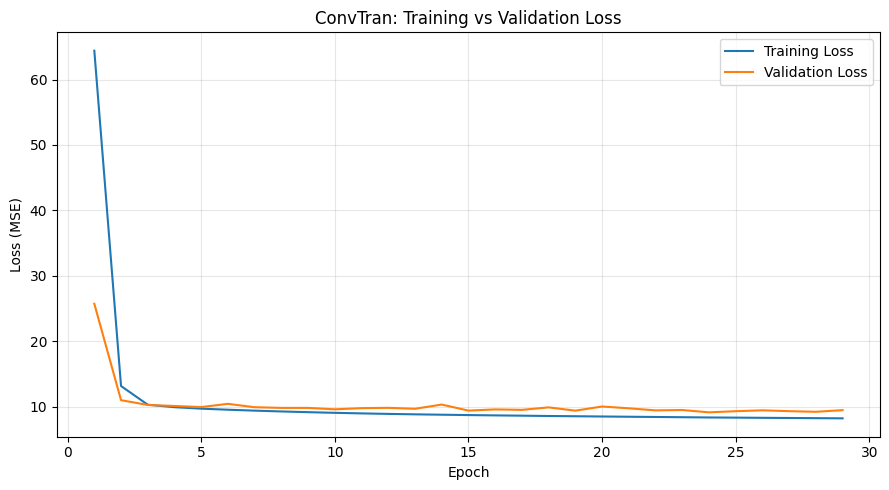

In [18]:
plot_convtran_loss(history)

In [19]:
checkpoint = torch.load(
    './checkpoints/model_best.pth',
    map_location=device
)

model.load_state_dict(checkpoint['state_dict'])
model.to(device)

test_evaluator = SupervisedTrainer(
    model=model,
    dataloader=test_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None,
    print_interval=10,
    console=True,
    print_conf_mat=False
)

RuntimeError: Error(s) in loading state_dict for ConvTran:
	size mismatch for Fix_Position.pe: copying a param with shape torch.Size([1, 1000, 16]) from checkpoint, the shape in current model is torch.Size([1, 625, 16]).
	size mismatch for attention_layer.relative_bias_table: copying a param with shape torch.Size([1999, 8]) from checkpoint, the shape in current model is torch.Size([1249, 8]).
	size mismatch for attention_layer.relative_index: copying a param with shape torch.Size([1000000, 1]) from checkpoint, the shape in current model is torch.Size([390625, 1]).

In [ ]:
test_metrics, test_results = test_evaluator.evaluate(
    epoch_num=None,
    keep_all=True
)

In [ ]:
y_true = test_results['targets']
y_pred = test_results['predictions']

print("True shape:", y_true.shape)
print("Pred shape:", y_pred.shape)

In [ ]:
# Convert to NumPy arrays if they are PyTorch tensors
if torch.is_tensor(y_true):
    y_true = y_true.detach().cpu().numpy()

if torch.is_tensor(y_pred):
    y_pred = y_pred.detach().cpu().numpy()

# Extract SBP and DBP separately
sbp_true = y_true[:, 0]
sbp_pred = y_pred[:, 0]

dbp_true = y_true[:, 1]
dbp_pred = y_pred[:, 1]

# SBP metrics and plots
print("===== SBP Metrics =====")
print_metrics(sbp_true, sbp_pred)

plot_regression_results(
    sbp_true,
    sbp_pred,
    model_name="ConvTran",
    target_name="SBP"
)

# DBP metrics and plots
print("===== DBP Metrics =====")
print_metrics(dbp_true, dbp_pred)

plot_regression_results(
    dbp_true,
    dbp_pred,
    model_name="ConvTran",
    target_name="DBP"
)

In [ ]:
from processing import evaluate_convtran_vitaldb
convtran_vitaldb_results = evaluate_convtran_vitaldb(
    model=model,  # Your trained, best-checkpoint ConvTran model
    base_dir=BASE_DIR,
    batch_size=64,
    device=device
)